
# PBMC tutorial: structural and programme heterogeneity

This tutorial runs scCHART on the 10x Genomics PBMC 5k scATAC data set and measures, within
each annotated cell type, two kinds of heterogeneity:

- **structural**: how much the cells differ from their population consensus in a chromatin-state
  representation (here LSI);
- **programme**: how much the cells of a population differ in their use of regulatory
  programmes (sets of accessible tiles).

For each population and axis scCHART reports the observed divergence `J`, its expectation
`E0[J]` under a fixed-margin technical null, and the calibrated excess `Δ = J − E0[J]`. Each
cell also gets its contribution `d_i` to its population's `J`. The two axes are reported
separately; scCHART defines no combined score.

**Input requirements.** An `AnnData` with integer accessibility counts in `X` (cells × peaks or
tiles), one population label per cell in `obs`, and, for the figures, an embedding in
`obsm`. The structural axis also needs a representation `Z` and the fixed projection that
produced it, so that null matrices can be projected the same way.

**Data.** Prepare the input once from the repository root (downloads about 840 MB, checks its
SHA-256 and writes a 65 MB file to `examples/pbmc_tutorial/data/`):

```bash
uv run python examples/pbmc_tutorial/prepare_data.py
```

**Run time.** The expensive step is the structural null calibration inside `model.fit`
(section 5). The structural matched-depth comparison is much slower and is off by default
(section 9). Cells with expensive steps print their measured time; in the stored run (scCHART
0.2.0, `SCCHART_N_JOBS=24`, one run on an Apple M3 Ultra), `model.fit` took 4.9 min and the
programme matched-depth comparison 8 s. Times depend on the machine and its load.
`SCCHART_N_JOBS` sets the number of parallel null chains, structural and programme (default: the
number of CPUs, at most 8);
results do not depend on it.

In [1]:
import os
import time
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

import scchart

print("scCHART", scchart.__version__)

DATA = Path(os.environ.get("SCCHART_PBMC_DATA", "data/pbmc5k_scchart_input.h5ad"))
RESULTS = DATA.with_name("pbmc5k_scchart_results.h5ad")
N_JOBS = int(os.environ.get("SCCHART_N_JOBS", min(8, os.cpu_count() or 1)))
RUN_STRUCTURAL_MATCHED_DEPTH = os.environ.get("SCCHART_TUTORIAL_MATCHED_DEPTH", "0") == "1"
pd.set_option("display.precision", 4)
scchart.pl.set_style()      # Arial, thin lines; savefig gives editable PDF/SVG and 600 dpi PNG

scCHART 0.2.0



## 1. Load the data

`prepare_data.py` retains 250,000 genome tiles (500 bp) selected by SnapATAC2 and nine annotated cell types with at least 140 cells each, excluding MAIT, NK, and pDC populations.

The matrix `X` contains integer fragment counts. scCHART uses binary accessibility (`X > 0`) for heterogeneity scoring, while fragment counts are retained for sequencing-depth calculations and downsampling.


In [2]:
adata = ad.read_h5ad(DATA)
labels = adata.obs["cell_type"].astype(str).to_numpy()
adata

AnnData object with n_obs × n_vars = 3921 × 250000
    obs: 'cell_type'
    uns: 'source'
    obsm: 'X_umap'

## 2. Populations, depth and embedding

Every scCHART quantity is defined **within** a declared population, relative to that
population's own consensus. Here the populations are the annotated cell types; scCHART never
infers them. Populations also differ in sequencing depth, which matters when they are compared
(section 9).

In [3]:
depth = np.asarray(adata.X.sum(axis=1)).ravel().astype(float)      # count depth per cell
n_open = np.diff(adata.X.tocsr().indptr)                              # open tiles per cell
ORDER = pd.Series(labels).value_counts().index.tolist()              # populations, largest first
qc = pd.DataFrame({
    "n_cells": pd.Series(labels).value_counts(),
    "median_count_depth": pd.Series(depth).groupby(labels).median(),
    "median_open_tiles": pd.Series(n_open).groupby(labels).median(),
}).reindex(ORDER)
qc.index.name = "population"
qc

,n_cells,median_count_depth,median_open_tiles
population,,,
cDC,842,14302.0,8801.5
CD14 Mono,658,12603.5,7844.5
CD4 Memory,599,8316.0,5157.0
CD8 Memory,526,10168.0,6163.5
CD4 Naive,444,6347.5,3997.5
Memory B,276,7556.5,4587.5
CD8 Naive,262,7457.5,4699.0
CD16 Mono,168,14177.0,8701.0
Naive B,146,9719.5,5844.0


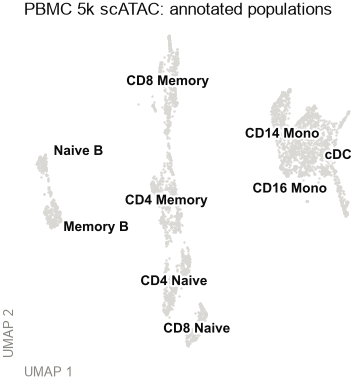

In [4]:
scchart.pl.embedding(adata, groupby="cell_type", title="PBMC 5k scATAC: annotated populations")
plt.show()

## 3. Structural representation

The structural axis uses a representation `Z` exactly as supplied. For calibration, `Z` must
come from a **fixed projection** that can also project null matrices without being refitted.
`LSIProjection` (TF-IDF and truncated SVD, frozen after fitting) is fitted here on all
3,921 cells with 50 components.

The leading LSI components of scATAC data usually track sequencing depth. This analysis
declares a rule that drops components whose absolute Pearson correlation with count depth
exceeds 0.30. That rule is a modelling choice, not part of scCHART; the structural results
are conditional on it.

In [5]:
proj_full = scchart.LSIProjection.fit(adata.X, n_components=50, random_state=1)
Z_full = proj_full(adata.X)
r_depth = np.array([pearsonr(Z_full[:, k], depth).statistic for k in range(Z_full.shape[1])])
kept = np.flatnonzero(np.abs(r_depth) <= 0.30)
proj = proj_full.with_components(kept)
adata.obsm["X_lsi"] = proj(adata.X)
print("dropped components (1-based):", (np.flatnonzero(np.abs(r_depth) > 0.30) + 1).tolist(),
      "| retained:", kept.size)

dropped components (1-based): [1, 2] | retained: 48



## 4. Configure scCHART

We configure `scchart.Heterogeneity` to calculate both structural and regulatory programme heterogeneity.

- **Structural axis:** `use_rep="X_lsi"` specifies the LSI representation, and `projection=proj` supplies the fixed projection used for null calibration.
- **Programme axis:** Without an external programme annotation, scCHART derives population-associated accessibility programmes from the data. For each eligible population, it selects up to 300 tiles based on their accessibility specificity. Programme definitions and background parameters are estimated using five stratified cross-fitting folds (`n_folds=5`, `random_state=0`), so cells are scored using references constructed without their own fold.
- **Null calibration:** scCHART uses fixed-margin randomization, preserving the number of accessible tiles per cell and the number of cells accessing each tile. The default `proposal_clock` sampler counts every attempted swap, whether accepted or rejected. This differs from `accepted_swap`, which counts only successful swaps. The analysis uses 20 null replicates per population.
- **Reproducibility:** `structural_seed=(20260928, 130)` specifies the structural random seed.

The order of populations affects the assignment of population-specific null seeds. We explicitly pass `populations=ORDER`, ordered by decreasing population size. Otherwise, scCHART uses sorted population labels. The population order and assigned seeds are recorded in the results.


In [6]:
model = scchart.Heterogeneity(
    use_rep="X_lsi",
    projection=proj,
    n_folds=5,
    random_state=0,
    structural_seed=(20260928, 130),
    n_jobs=N_JOBS,
    verbose=True,
)
print(model)

Heterogeneity
Population-conditioned structural and programme heterogeneity (reported separately).

Axes
  Structural                        Z = adata.obsm['X_lsi'], adapter signed_channel
                                    null through fixed projection LSIProjection
  Programme                         endogenous group-specific (provisional); 5-fold cross-fit, random_state=0

Settings
  Accessibility matrix              adata.X
  Calibration                       fixed-margin null
  Null sampler                      proposal_clock
  Structural seed                   (20260928, 130)
  Programme seed                    10000000
  Programme null cells              scored

Planned analyses
  01. Validate inputs
  02. Structural scores (d_i, J_G)
  03. Structural null calibration (E0[J_G], Delta_G)
  04. Programme references and scores (P_i, d_i^(P), J_G^(P))
  05. Programme null calibration (E0[J_G^(P)], Delta_G^(P))
  06. Store results

Fit status
  Fitted                            Not 

## 5. Fit both axes

This is the expensive step: the structural null randomises each population's binary
cells × tiles matrix with fixed margins 20 times and projects every null matrix with the same
fixed projection. The progress lines show `J`, `E0` and `Δ` of each population as it
finishes.

In [7]:
t = time.time()
model.fit(adata, groupby="cell_type", populations=ORDER)
print(f"fit time: {(time.time() - t) / 60:.1f} min with n_jobs={N_JOBS}")

[scCHART 01/06] Validate inputs


    Cells x features                 3,921 x 250,000


    Population key                   adata.obs['cell_type'] (9 populations)


    Population order                 declared with populations=: cDC, CD14 Mono, CD4 Memory, CD8 Memory, CD4 Naive, Memory B, CD8 Naive, CD16 Mono, Naive B


[scCHART 02/06] Structural scores (d_i, J_G)


    Representation                   adata.obsm['X_lsi'], 48 dimensions


... (32 outputs left out)

    Population tables, nulls, seeds  adata.uns['scchart']


    Fitted attributes                model.structural_, model.programme_


[scCHART] Fit complete in 295.6 s.


fit time: 4.9 min with n_jobs=24



## 6. Population results

`J_obs` is the observed structural divergence (bits), `E0_J` is the mean divergence estimated from the null replicates, and `Delta_G = J_obs − E0_J` is the calibrated structural excess.

The corresponding programme heterogeneity quantities are `J_P_obs`, `E0_J_P`, and `Delta_P`.

`sd0_diagnostic` reports the standard deviation of divergence values across the 20 null replicates. It describes variability under the sampled null model, not the magnitude of heterogeneity or the precision of the estimated null mean.


In [8]:
model.structural_[["n_cells", "J_obs", "E0_J", "Delta_G", "sd0_diagnostic"]]

,n_cells,J_obs,E0_J,Delta_G,sd0_diagnostic
population,,,,,
cDC,842,0.9726,0.5330,0.4396,0.0030
CD14 Mono,658,0.6694,0.3258,0.3436,0.0030
CD4 Memory,599,1.3842,0.3056,1.0787,0.0024
CD8 Memory,526,0.4211,0.0589,0.3623,0.0006
CD4 Naive,444,1.0364,0.1651,0.8713,0.0018
Memory B,276,0.1653,0.0151,0.1502,0.0002
CD8 Naive,262,0.7216,0.1653,0.5563,0.0021
CD16 Mono,168,1.1048,0.7144,0.3904,0.0092
Naive B,146,0.1318,0.0177,0.1141,0.0003


On the programme axis a cell with no programme evidence above background is *unscorable*
and is never imputed, so every population reports its `scored_fraction`. `median_P` is the
median within-cell programme mixing `P_i` (section 8).

In [9]:
print("K =", len(model.programme_model_.programmes_), "programmes:", ", ".join(model.programme_model_.programmes_))
model.programme_[["n_cells", "scored_fraction", "J_P_obs", "E0_J_P", "Delta_P", "sd0_diagnostic", "median_P"]]

K = 9 programmes: CD14 Mono, CD16 Mono, CD4 Memory, CD4 Naive, CD8 Memory, CD8 Naive, Memory B, Naive B, cDC


,n_cells,scored_fraction,J_P_obs,E0_J_P,Delta_P,sd0_diagnostic,median_P
population,,,,,,,
cDC,842,1.0,0.3987,0.2428,0.1559,0.0093,0.4175
CD14 Mono,658,1.0,0.3161,0.2166,0.0995,0.0071,0.3121
CD4 Memory,599,1.0,0.6042,0.2657,0.3386,0.0064,0.3926
CD8 Memory,526,1.0,0.1715,0.0884,0.0830,0.0027,0.1516
CD4 Naive,444,1.0,0.1985,0.1425,0.0560,0.0057,0.3785
Memory B,276,1.0,0.0764,0.0626,0.0138,0.0026,0.2448
CD8 Naive,262,1.0,0.1400,0.1048,0.0352,0.0051,0.3847
CD16 Mono,168,1.0,0.2215,0.1189,0.1027,0.0037,0.3084
Naive B,146,1.0,0.1065,0.0625,0.0440,0.0029,0.3460


Everything is also stored on `adata`: per-cell outputs in `obs` and `obsm`, and population
tables, null replicates, population order and seeds in `uns["scchart"]`.

In [10]:
print(adata)
fit = adata.uns["scchart"]
print("\npopulation order:", ", ".join(fit["population_order"]))
print("structural seed keys:", fit["structural"]["seed_keys"].tolist()[:2], "...")
print("programme base seeds (folds 0-4) of", fit["population_order"][0], ":", fit["programme"]["base_seeds"][0].tolist())

AnnData object with n_obs × n_vars = 3921 × 250000
    obs: 'cell_type', 'scchart_structural_d', 'scchart_structural_entropy', 'scchart_structural_population_J_obs', 'scchart_programme_P', 'scchart_programme_d', 'scchart_programme_population_J_P_obs', 'scchart_programme_scored', 'scchart_programme_dominant', 'scchart_programme_dominant_weight', 'scchart_programme_total_evidence', 'scchart_programme_background_depth'
    uns: 'source', 'scchart_structural', 'scchart_programme', 'scchart'
    obsm: 'X_umap', 'X_lsi', 'scchart_structural_probabilities', 'scchart_programme_composition', 'scchart_programme_evidence'

population order: cDC, CD14 Mono, CD4 Memory, CD8 Memory, CD4 Naive, Memory B, CD8 Naive, CD16 Mono, Naive B
structural seed keys: [[20260928, 130, 0], [20260928, 130, 1]] ...
programme base seeds (folds 0-4) of cDC : [10000000, 10010000, 10020000, 10030000, 10040000]


## 7. Calibration figures

Open circles are the null expectation `E0[J]` (bar: null standard deviation), filled circles
the observed `J`; the line between them is the calibrated excess `Δ`. Raw `J` mixes biology
with sparse sampling, so raw `J` and `Δ` can order populations differently.

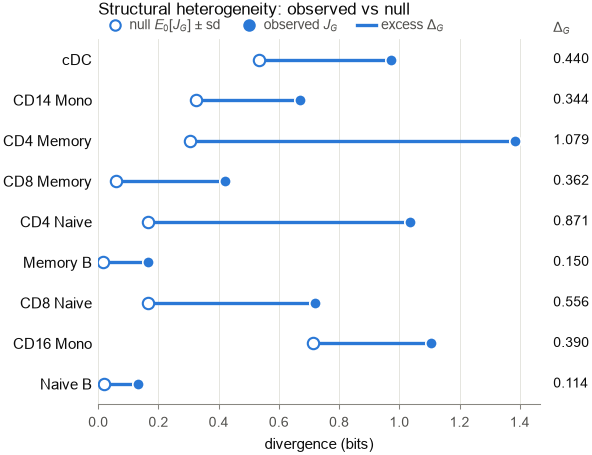

In [11]:
scchart.pl.calibration(adata, "structural")
plt.show()

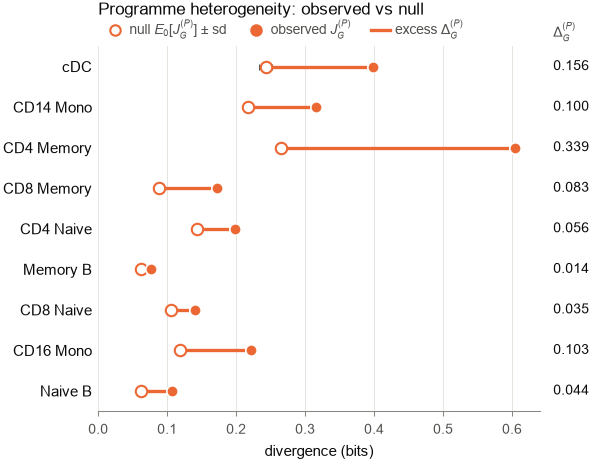

In [12]:
scchart.pl.calibration(adata, "programme")
plt.show()

Each population's 20 null replicates (grey) against its observed `J`:

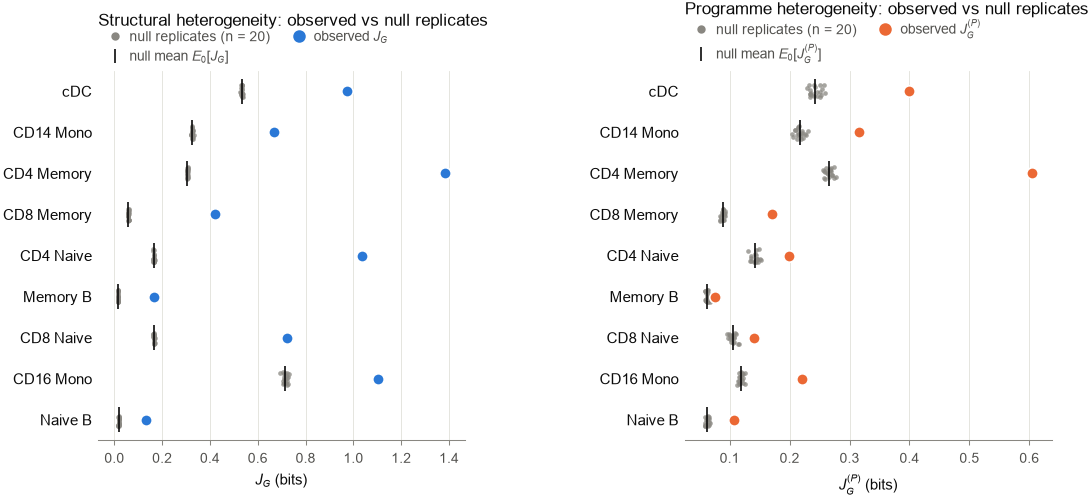

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
fig.subplots_adjust(wspace=0.6)
scchart.pl.null_distribution(adata, "structural", ax=axes[0])
scchart.pl.null_distribution(adata, "programme", ax=axes[1])
plt.show()


## 8. Per-cell contributions and programme mixing

The per-cell divergences `d_i(G)` and `d_i^(P)(G)` decompose the observed population heterogeneity: their mean within each population equals `J_obs` and `J_P_obs`, respectively (for the programme axis, the mean is calculated over successfully scored cells).

These values identify cells that contribute more or less to the observed heterogeneity within their population. They are not individually null-calibrated, and their interpretation is relative to each population's own consensus rather than a common reference across populations.


max |mean d - J|: 5.273559366969494e-16


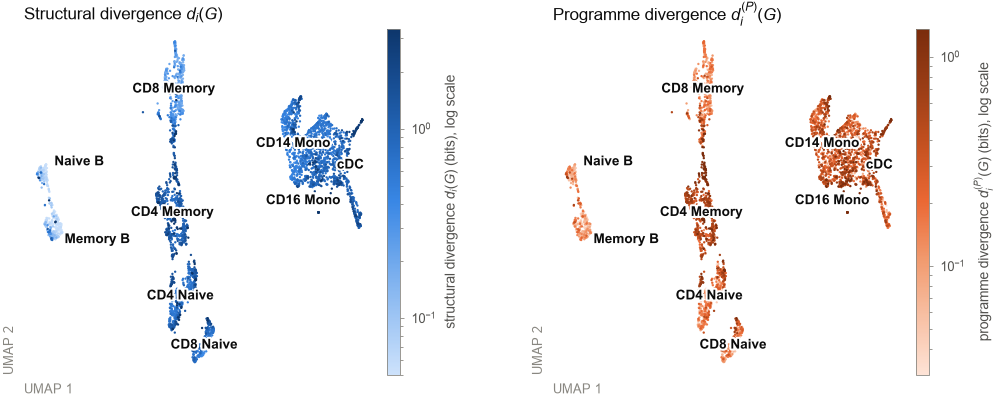

In [14]:
check = pd.DataFrame({
    "mean d_i": adata.obs.groupby(labels)["scchart_structural_d"].mean(),
    "J_obs": model.structural_["J_obs"],
    "mean d_i^(P)": adata.obs.groupby(labels)["scchart_programme_d"].mean(),
    "J_P_obs": model.programme_["J_P_obs"],
}).reindex(ORDER)
print("max |mean d - J|:", float(max((check["mean d_i"] - check["J_obs"]).abs().max(),
                                     (check["mean d_i^(P)"] - check["J_P_obs"]).abs().max())))
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0))
fig.subplots_adjust(wspace=0.4)
scchart.pl.embedding(adata, "scchart_structural_d", groupby="cell_type", log=True, ax=axes[0])
scchart.pl.embedding(adata, "scchart_programme_d", groupby="cell_type", log=True, ax=axes[1])
plt.show()


`P_i = H(r_i) / log2 K` measures programme diversity within an individual cell: how evenly its accessibility evidence is distributed across K programmes (0 = one programme; 1 = equal usage of all programmes).

This is distinct from population-level programme heterogeneity, which measures differences in programme composition between cells. For example, a population of identical cells using all programmes equally has `P_i = 1` but `J^(P) = 0`.

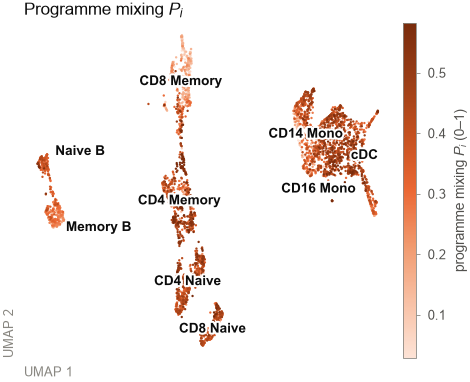

,median_P,J_P_obs,Delta_P
population,,,
cDC,0.4175,0.3987,0.1559
CD14 Mono,0.3121,0.3161,0.0995
CD4 Memory,0.3926,0.6042,0.3386
CD8 Memory,0.1516,0.1715,0.0830
CD4 Naive,0.3785,0.1985,0.0560
Memory B,0.2448,0.0764,0.0138
CD8 Naive,0.3847,0.1400,0.0352
CD16 Mono,0.3084,0.2215,0.1027
Naive B,0.3460,0.1065,0.0440


In [15]:
scchart.pl.embedding(adata, "scchart_programme_P", groupby="cell_type")
plt.show()
model.programme_[["median_P", "J_P_obs", "Delta_P"]]


The heatmap shows the mean programme composition of each population, calculated over successfully scored cells.

With endogenous programmes, each programme is named after the population from which its accessibility signature was derived. Rows represent cell populations, and columns represent programmes, arranged in the same order.

Diagonal entries indicate the mean weight assigned to a population's own programme. Off-diagonal entries indicate evidence for programmes derived from other populations. These patterns can reveal similarities in accessibility programme usage, but do not by themselves establish biological relationships between populations.


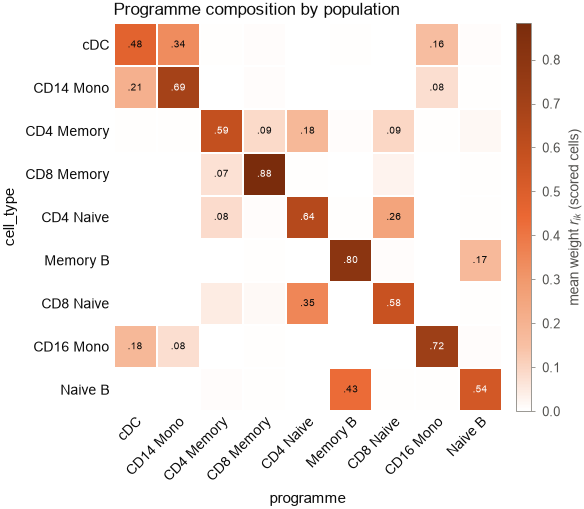

In [16]:
scchart.pl.programme_composition(adata)
plt.show()


## 9. Comparing populations at matched depth

Calibrated heterogeneity (`Delta_G` and `Delta_P`) can remain sensitive to sequencing depth. To support comparisons between populations, scCHART provides matched-depth analysis.

Populations with median count depth above a common target `D*` are downsampled using binomial thinning. Heterogeneity and null calibration are then recomputed while keeping the structural projection, programme references, and background parameters fixed. Populations below the target depth are not upsampled.

Here, `D*` is set to the lowest median count depth among the populations. This allows comparisons at a common target without requiring upsampling.

Matched-depth analysis reduces depth-related differences but does not guarantee that all biological variation remains detectable at the selected depth. 

For programme matched-depth analysis, we reuse the cross-fitted programme references from the original fit (`model.references_`).


In [17]:
D_star = float(qc["median_count_depth"].min())
print(f"D* = {D_star:g} counts ({qc['median_count_depth'].idxmin()})")
t = time.time()
md_P = scchart.depth_standardized_programme_comparison(
    adata.X, labels, model.references_, D_star, populations=ORDER, n_replicates=5, n_jobs=N_JOBS)
print(f"programme matched depth: {time.time() - t:.0f} s")
md_P.summary[["q", "Delta_P_mean", "Delta_P_sd", "scored_fraction_min"]].assign(
    Delta_P_full_depth=model.programme_["Delta_P"])

D* = 6347.5 counts (CD4 Naive)


programme matched depth: 8 s


,q,Delta_P_mean,Delta_P_sd,scored_fraction_min,Delta_P_full_depth
population,,,,,
cDC,0.4438,0.1344,0.0110,0.9988,0.1559
CD14 Mono,0.5036,0.0902,0.0061,0.9985,0.0995
CD4 Memory,0.7633,0.3237,0.0054,1.0000,0.3386
CD8 Memory,0.6243,0.0789,0.0046,1.0000,0.0830
CD4 Naive,1.0000,0.0561,0.0008,1.0000,0.0560
Memory B,0.8400,0.0133,0.0007,1.0000,0.0138
CD8 Naive,0.8512,0.0345,0.0013,1.0000,0.0352
CD16 Mono,0.4477,0.1169,0.0081,1.0000,0.1027
Naive B,0.6531,0.0422,0.0037,1.0000,0.0440


The structural comparison repeats the structural null for 5 downsampling replicates of
every population, which takes much longer than the fit. It runs only when the environment
variable `SCCHART_TUTORIAL_MATCHED_DEPTH=1` is set.

In [18]:
if RUN_STRUCTURAL_MATCHED_DEPTH:
    t = time.time()
    md_S = scchart.depth_standardized_structural_comparison(
        adata.X, labels, proj, D_star, populations=ORDER, n_replicates=5, seed=20260925, n_jobs=N_JOBS)
    print(f"structural matched depth: {(time.time() - t) / 60:.0f} min")
    display(md_S.summary[["q", "Delta_G_mean", "Delta_G_sd", "zero_open_excluded"]])
else:
    md_S = None
    print("structural matched depth not run (set SCCHART_TUTORIAL_MATCHED_DEPTH=1)")

structural matched depth not run (set SCCHART_TUTORIAL_MATCHED_DEPTH=1)



## 10. Structural versus programme heterogeneity

Each point represents one cell population, with its calibrated structural excess (`Delta_G`) and programme excess (`Delta_P`) calculated at the observed sequencing depth. Points are coloured by lineage.

The two axes are displayed together but are not combined into a single score. They capture distinct properties of chromatin heterogeneity: populations may differ in their structural variation without showing corresponding differences in programme usage, or vice versa.

Because these values are calculated at the observed depth, differences between populations should be interpreted with consideration of sequencing-depth effects.


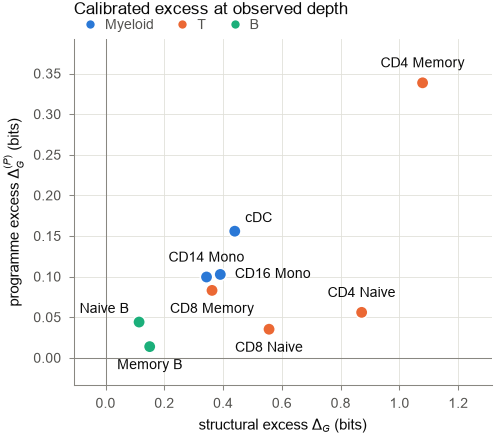

In [19]:
LINEAGE = {"CD4 Memory": "T", "CD4 Naive": "T", "CD8 Memory": "T", "CD8 Naive": "T",
           "cDC": "Myeloid", "CD14 Mono": "Myeloid", "CD16 Mono": "Myeloid", "Memory B": "B", "Naive B": "B"}
scchart.pl.structural_vs_programme(adata, groups=LINEAGE)
plt.show()


## 11. Save and reload

scCHART stores per-cell scores, population summaries, programme compositions, and analysis metadata in `adata`. These results are preserved when the object is saved using `write_h5ad()` and can be inspected after reloading.

However, the fitted structural projection and programme reference objects (`model.references_`) are not automatically serialized into the `.h5ad` file.

The saved results can be used for downstream inspection and visualization. Running additional null calibrations or matched-depth analyses requires the relevant fitted objects to be available again.

To reproduce these objects, retain the original input data, preprocessing steps, model parameters, and random seeds.


saved to data/pbmc5k_scchart_results.h5ad


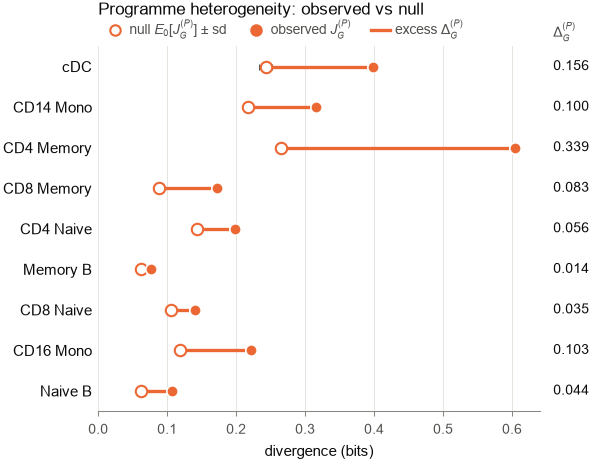

In [20]:
adata.write_h5ad(RESULTS, compression="gzip")
reloaded = ad.read_h5ad(RESULTS)
saved = pd.DataFrame(reloaded.uns["scchart"]["structural"]["table"]).set_index("population")
assert np.array_equal(saved["Delta_G"].to_numpy(), model.structural_["Delta_G"].to_numpy())
print("saved to", RESULTS)
scchart.pl.calibration(reloaded, "programme")     # figures can be drawn from the saved file
plt.show()


## Interpretation

The following observations are based on the results stored in this notebook. Structural matched-depth comparison was not performed.

- **Null calibration changes structural rankings.** CD16 Mono has the second-highest observed structural divergence (`J_obs = 1.10` bits), but also the highest null expectation (`E0_J = 0.71`). Its calibrated structural excess (`Delta_G = 0.39`) ranks fifth among the nine populations. This illustrates why observed divergence alone may give a different picture from null-calibrated heterogeneity.

- **Structural heterogeneity varies across populations.** CD4 Memory (`Delta_G = 1.08`), CD4 Naive (0.87), and CD8 Naive (0.56) have the highest calibrated structural excess. Memory B (0.15) and Naive B (0.11) have the lowest values.

- **Programme heterogeneity shows a different ordering.** CD4 Memory has the highest calibrated programme excess (`Delta_P = 0.34`), followed by cDC (0.16), CD16 Mono (0.10), and CD14 Mono (0.10). All cells were successfully scored (`scored_fraction = 1`). The programme matched-depth analysis uses `D* = 6,347.5` counts. Its rankings should be interpreted alongside the replicate-level results and depth-related limitations.

- **The two axes capture different patterns.** CD4 Naive and CD8 Naive show relatively high structural excess (`Delta_G = 0.87` and 0.56, respectively) but low programme excess (`Delta_P = 0.056` and 0.035). In contrast, cDC ranks second on programme excess but fourth on structural excess. These differences in population rankings suggest that structural variation and programme-composition variation capture distinct properties. Their numerical magnitudes should not be directly compared across axes.

- **Within-cell programme mixing differs from population heterogeneity.** CD8 Naive has the third-highest median programme mixing (`P_i = 0.38`) but the third-lowest observed programme divergence (`J_P_obs = 0.14`). Thus, cells may distribute accessibility evidence across several programmes while maintaining relatively similar programme compositions within their population.

- **Populations show overlapping programme signatures.** The programme-composition heatmap shows that CD4 Naive assigns a mean weight of 0.26 to the CD8 Naive programme, while CD8 Naive assigns 0.35 to the CD4 Naive programme. Naive B assigns 0.43 to the Memory B programme, and cDC assigns 0.34 to the CD14 Mono programme. These off-diagonal weights indicate overlapping accessibility signatures, but do not independently establish biological relationships.

These observations depend on the specified cell-type annotations, LSI representation and depth-associated component filtering, endogenous programme definitions, null calibration, and random seeds.

Per-cell divergence scores identify cells contributing more strongly to observed population heterogeneity. They are relative to each population's consensus and are not individually null-calibrated.



## What to report

For reproducibility, report the following settings alongside scCHART results:

- **Population definitions:** Annotated cell types used to define the nine populations.
- **Structural representation:** LSI with 50 initial components (`random_state=1`), excluding components with absolute Pearson correlation to sequencing depth greater than 0.30.
- **Probability transformation:** `signed_channel` simplex adapter.
- **Feature universe:** 250,000 selected genomic tiles (500 bp).
- **Programme reference:** Endogenous population-associated accessibility programmes, with up to 300 tiles per programme and five cross-fitting folds.
- **Null calibration:** Fixed-margin randomization using the `proposal_clock` sampler, with 100 attempted swaps per nonzero entry and 20 null replicates per population.
- **Reproducibility:** Population ordering, random seeds, and scCHART version.
- **Matched-depth analysis (when performed):** Target depth `D*`, number of downsampling replicates, and whether any populations could not reach the target depth.

Population comparisons should be interpreted in light of sequencing depth, the selected representation, programme definitions, and the assumptions of the null model.


In [21]:
print("scCHART", scchart.__version__, "| null sampler:", adata.uns["scchart"]["config"]["null_sampler"],
      "| D* =", D_star)

scCHART 0.2.0 | null sampler: proposal_clock | D* = 6347.5
